In [ ]:
%load_ext autoreload
%autoreload 2

### Figure 5: Updating with assay-specific data enables transfer to unseen alleles.

 - __a)__ EpiScan allele transfer learning to SARS-CoV-2 set.
 - __b)__ Yeast display single allele holdout transfer learning results.
 - __c)__ BA single allele holdout transfer learning results.
 - __d)__ ESCAPE-seq single allele holdout transfer learning results.

__Note:__ P-value bars are added separately for certain plots. The actual values can be found in each section and in the associated data folder.

In [ ]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()
while PROJECT_ROOT.name != "PepCL_Manuscript":
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise RuntimeError("Could not find PepCL_Manuscript project root.")
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

DATA_DIR = PROJECT_ROOT / "Data"
SRC_DIR = PROJECT_ROOT / "src"
FIGURES_DIR = PROJECT_ROOT / "Figures"
MODEL_CHECKPOINTS_DIR = PROJECT_ROOT / "Model_Checkpoints"

print("PROJECT_ROOT:", PROJECT_ROOT)
print("PROJECT_ROOT in sys.path:", str(PROJECT_ROOT) in sys.path)

PROJECT_ROOT: /home/pchati/PepCL_Manuscript
PROJECT_ROOT in sys.path: True


In [ ]:
# get mhc pseudosequences
from Data.mhc_pseudo_seqs import mhc_seq_dict
mhc_seq_dict={k.removeprefix("HLA-").replace("*","").replace(":",""):v for k,v in mhc_seq_dict.items()}

# get utils
from src.general_utils import *

# get feature data and processed feature table
from src.get_feature_data import *

# plotting fns
from src.plotting import *

# misc
import warnings
warnings.filterwarnings("ignore")
device="cuda"

In [ ]:
"""
Set figure output directory
"""
# create central repository and for this figure
central_figure_dir="Figure5"

# associated data dir
associated_data_dir=f"{central_figure_dir}/Associated_Data"

### Central legend

 - This legend corresponds to all plots below.

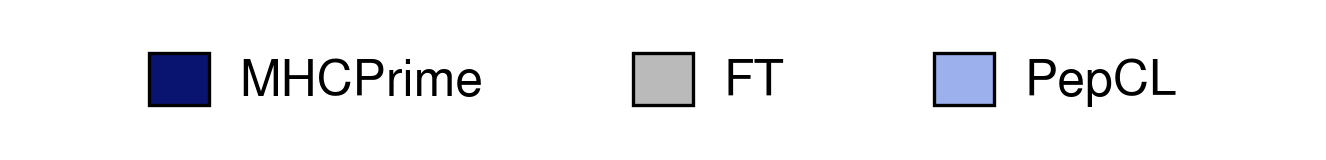

In [ ]:
# legend resized and formatted in illustrator
plot_horizontal_legend(
    legend_dict={
        'MHCPrime':'#081470',
        'FT': '#bababa',
        'PepCL': '#9bb0ed',
    },
    swatch_size=12,
    text_size=12,
    item_spacing=30,
    swatch_text_gap=6,
    swatch_outline_color='black',
    swatch_outline_width=0.8,
    figsize=None,
    dpi=300,
    default_font='Nimbus Sans',
    save_path=None,
    # save_path=f"{central_figure_dir}/fig5_legend",

)

### Fig. 5a: EpiScan

In [ ]:
# ms/episcan cov test sets
datasets_dir = DATA_DIR / "Training_Datasets" / "Processed" / "MS_Train_Test_Sets"
ms_test_data=pd.read_csv(f"{datasets_dir}/ms_test_data.csv", index_col=0)

episcan_train_test_dir = DATA_DIR / "Training_Datasets" / "Processed" / "EpiScan"
sd3_formatted=pd.read_csv(f"{episcan_train_test_dir}/sd3_formatted.csv", index_col=0)

In [ ]:
# get iteratively sampled map of alleles not in update set
score_cols=["mhcprime", "episcan_r9_ft", "episcan_r9_pepcl", "episcan_r9rt_ft", "episcan_r9rt_pepcl"]
sd3_formatted["seq_len"]=sd3_formatted.seq.str.replace("$", "").apply(len)
sd3_allele_ap_matrix=iterative_neg_subsample_map_per_allele(sd3_formatted[~sd3_formatted.allele.isin(["A0201", "A0301", "B0801",])].query("seq_len == 9"), score_cols, label_col='label', allele_col='allele', neg_ratio=99, n_iterations=100, seed=42)

Iterations: 100%|██████████| 100/100 [00:06<00:00, 14.83it/s]


In [ ]:
# get deltas from base
base_model_col="mhcprime"
sd3_allele_ap_matrix["ft_base_delta_r9"]=sd3_allele_ap_matrix["episcan_r9_ft"] - sd3_allele_ap_matrix[base_model_col]
sd3_allele_ap_matrix["pepcl_base_delta_r9"]=sd3_allele_ap_matrix["episcan_r9_pepcl"] - sd3_allele_ap_matrix[base_model_col]

sd3_allele_ap_matrix["ft_base_delta_r9rt"]=sd3_allele_ap_matrix["episcan_r9rt_ft"] - sd3_allele_ap_matrix[base_model_col]
sd3_allele_ap_matrix["pepcl_base_delta_r9rt"]=sd3_allele_ap_matrix["episcan_r9rt_pepcl"] - sd3_allele_ap_matrix[base_model_col]

In [ ]:
# matched ms performance
allele_set=sd3_formatted[~sd3_formatted.allele.isin(["A0201", "A0301", "B0801",])].query("seq_len == 9").allele.unique().tolist()
ms_test_data["seq_len"]=ms_test_data.seq.str.replace("$", "").apply(len)

ms_episcan_allele_ap_df=compute_ap_matrix_optimized(ms_test_data[ms_test_data.allele.isin(allele_set)].query("seq_len == 9"), score_cols, label_col="label", allele_col='allele')

100%|██████████| 8/8 [00:00<00:00, 115.99it/s]


In [ ]:
# reformat alleles
def format_allele_index(df):
    def convert(a):
        return f"{a[0]}*{a[1:3]}:{a[3:]}"
    df.index = df.index.map(convert)
    return df

sd3_allele_ap_matrix=format_allele_index(sd3_allele_ap_matrix)

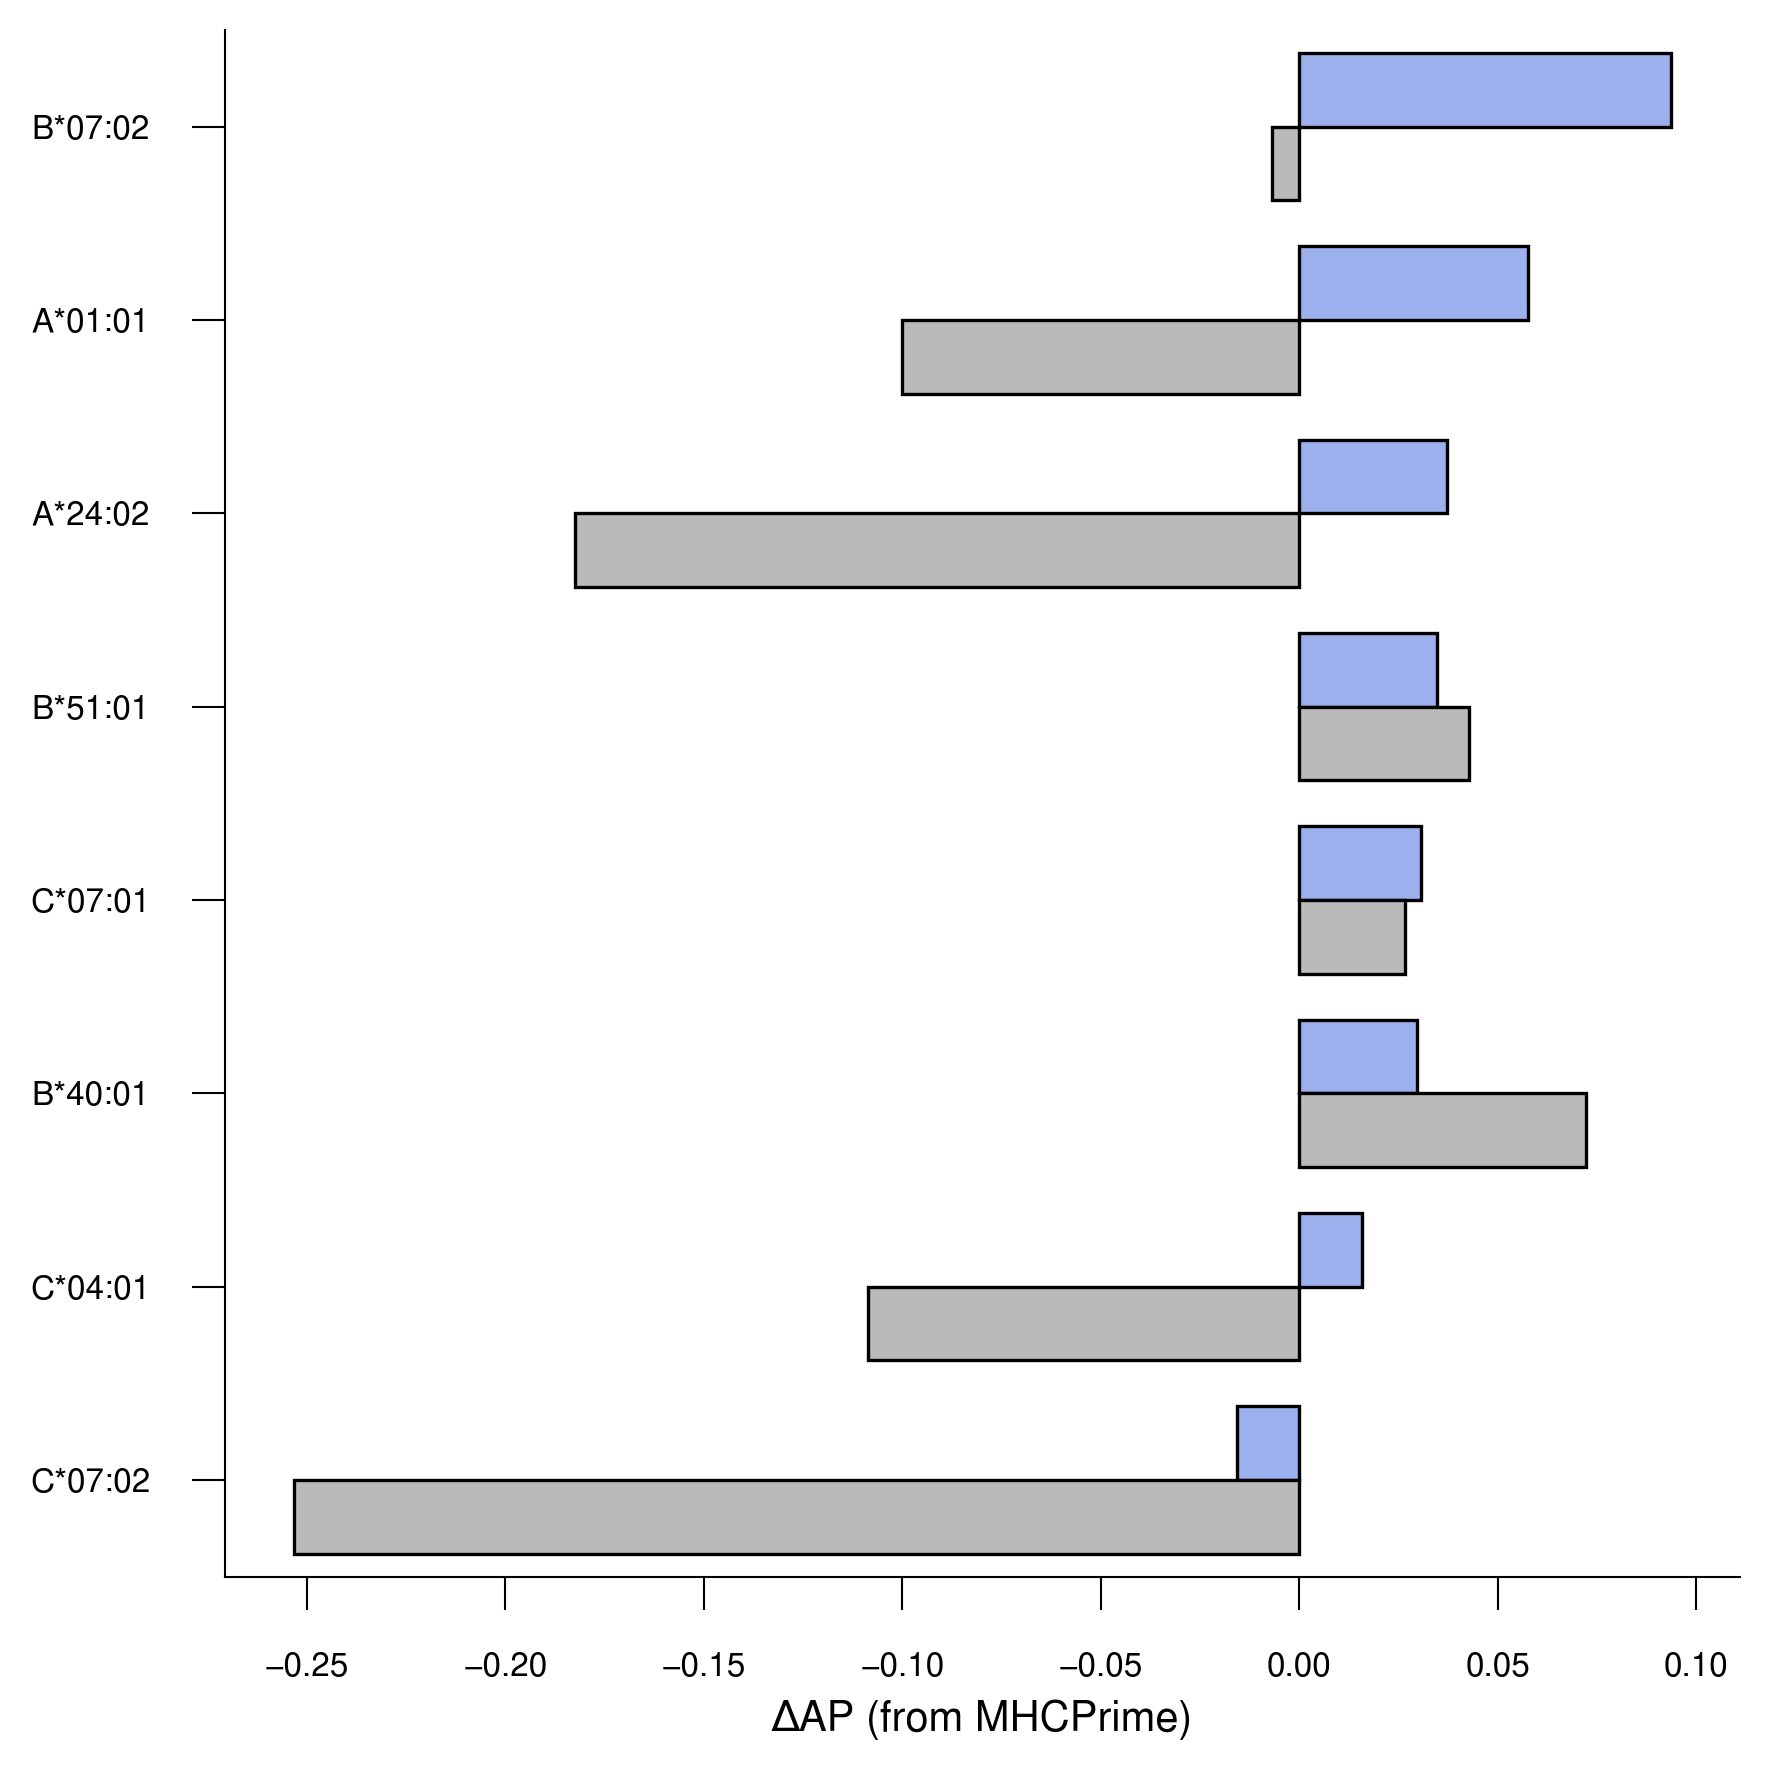

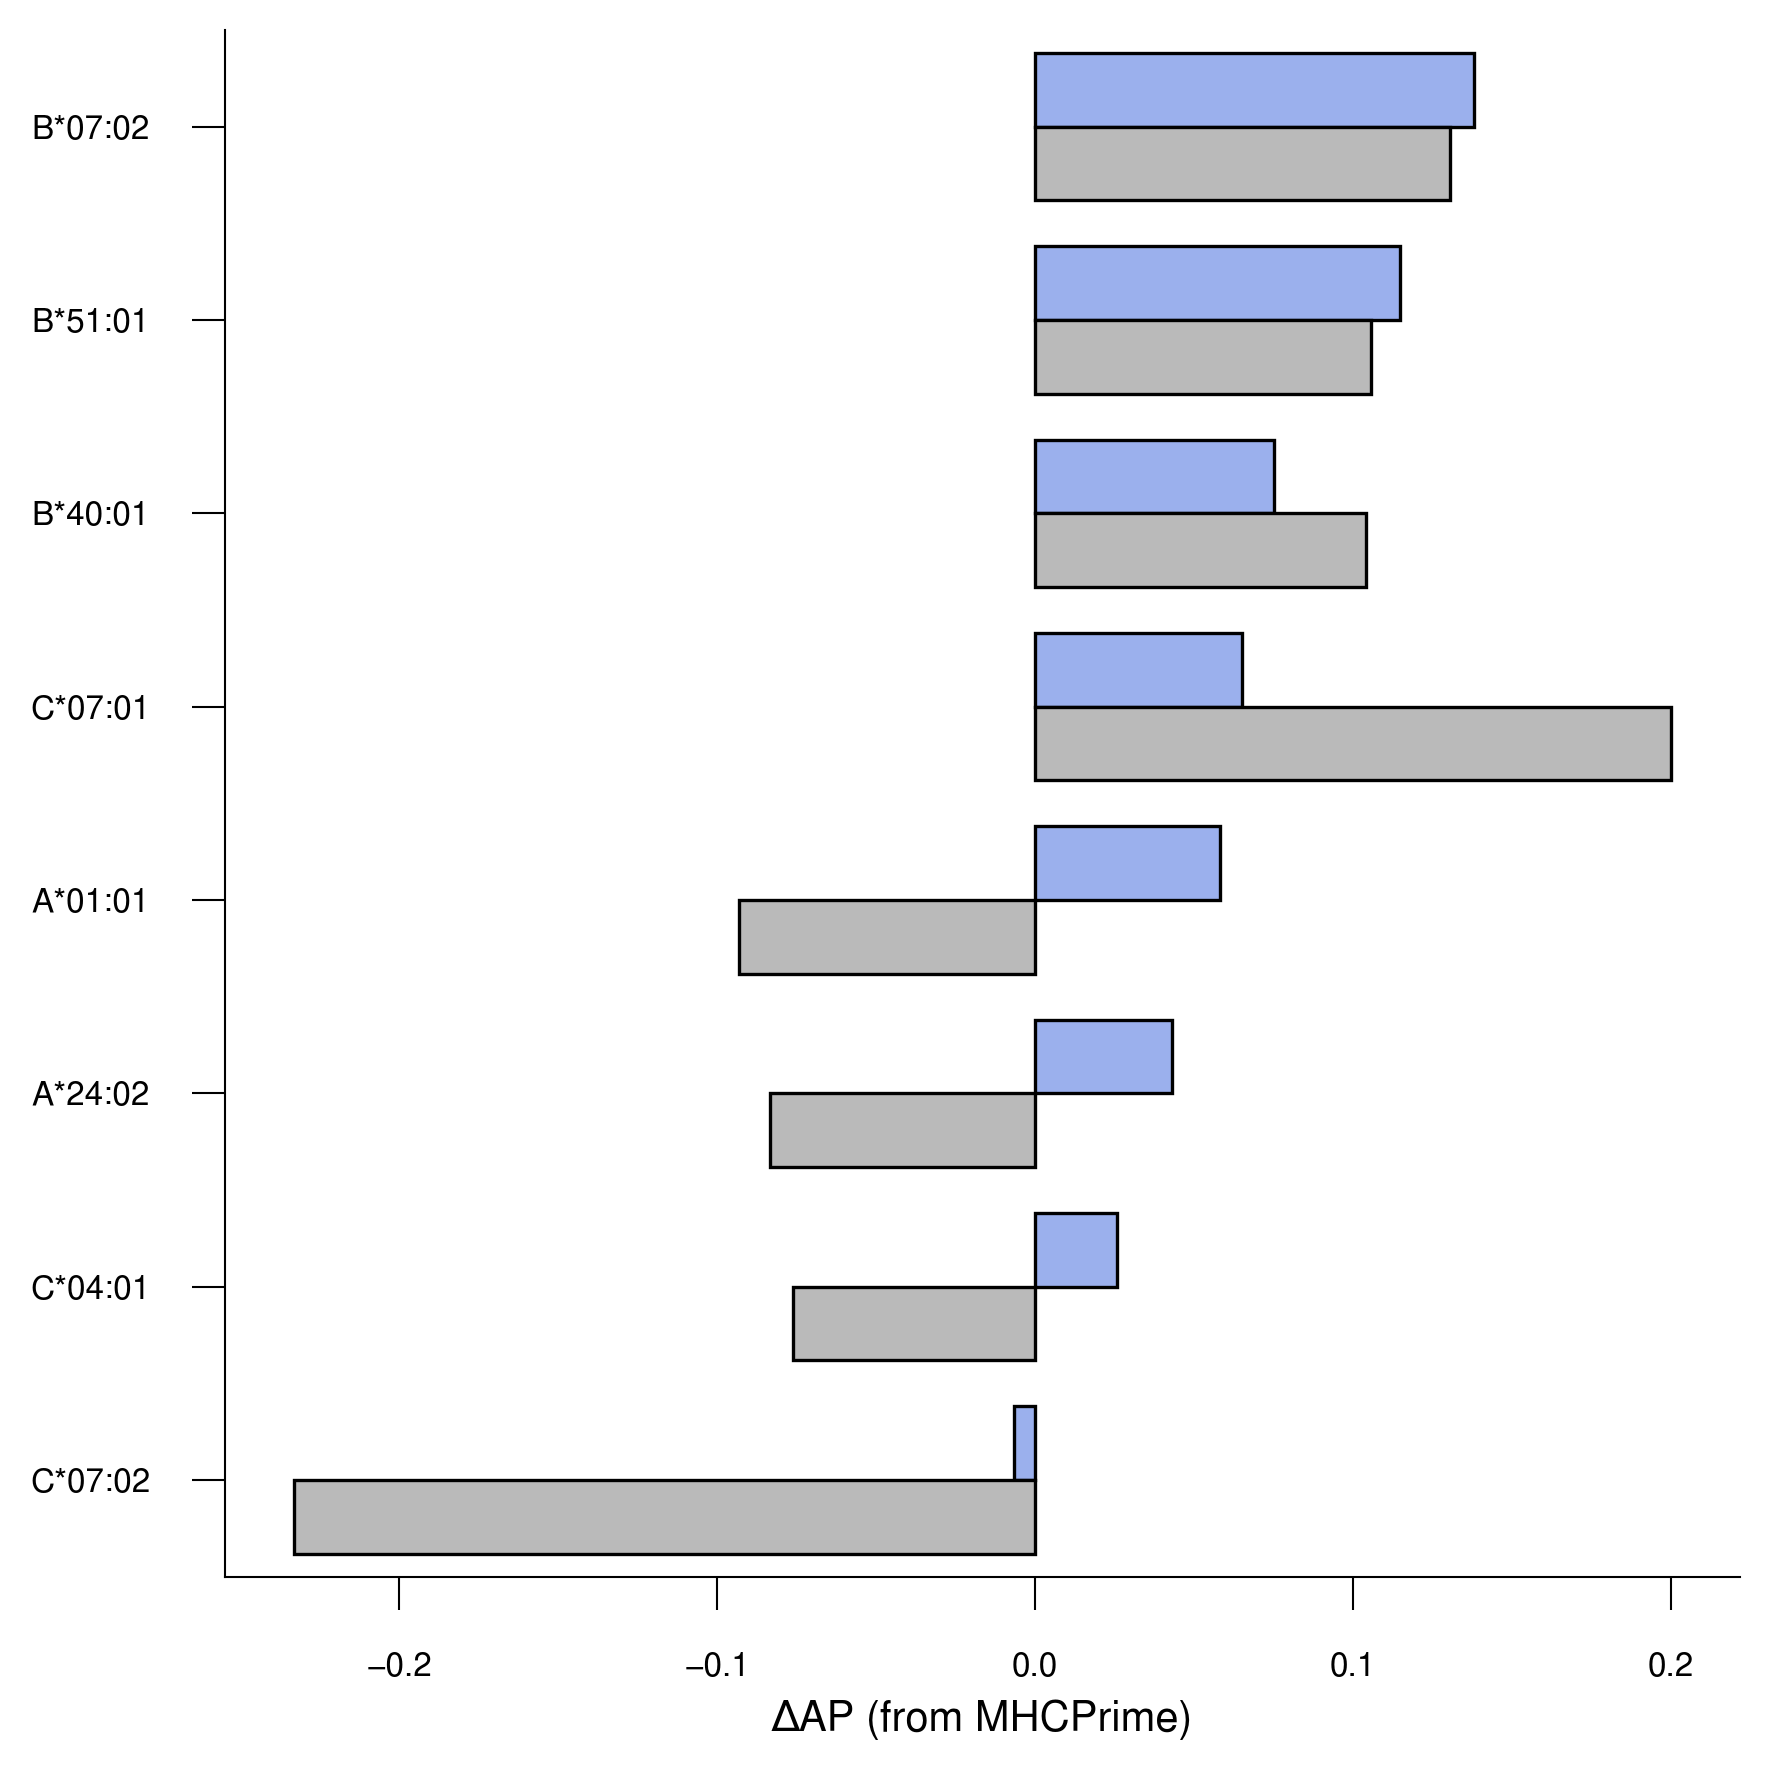

In [ ]:
# plot delta map barplots
plot_params=dict(
    figsize=(6, 6),
    dpi=300,
    default_font='Nimbus Sans',
    bar_width=0.8,
    bar_edgecolor='black',
    bar_edgewidth=0.8,
    alpha=1.0,
    group_spacing=0.5,
    colors=["#9bb0ed", "#bababa"],
    horizontal=True,
    xlabel='ΔAP (from MHCPrime)',
    ylabel="",
    xlabel_fontsize=10,
    ylabel_fontsize=10,
    xlabel_pad=4.0,
    ylabel_pad=4.0,
    title='',
    title_fontsize=12,
    title_bold=True,
    xtick_labelsize=8,
    ytick_labelsize=8,
    tick_length=8.0,
    tick_width=0.5,
    tick_direction='out',
    rotation=0,
    axis_linewidth=0.5,
    ylim=None,
    xlim=None,
    grid_alpha=0.0,
    legend_mode=None,
)

# plot_params["title"]="R9"
plot_bar_grouped_advanced(
    sd3_allele_ap_matrix.sort_values(by="pepcl_base_delta_r9", ascending=False),
    ["pepcl_base_delta_r9", "ft_base_delta_r9"],
    save_path=None,
    # save_path=f"{central_figure_dir}/fig5_a_episcan_cov_transfer_learning_base_delta_r9_per_allele",
    **plot_params,

)

# plot_params["title"]="R9/RT"
plot_bar_grouped_advanced(
    sd3_allele_ap_matrix.sort_values(by="pepcl_base_delta_r9rt", ascending=False),
    ["pepcl_base_delta_r9rt", "ft_base_delta_r9rt"],
    save_path=None,
    # save_path=f"{central_figure_dir}/fig5_a_episcan_cov_transfer_learning_base_delta_r9rt_per_allele",
    **plot_params,
)


{'MHCPrime': ['mhcprime'], 'FT R9': ['episcan_r9_ft'], 'PepCL R9': ['episcan_r9_pepcl'], 'FT R9RT': ['episcan_r9rt_ft'], 'PepCL R9RT': ['episcan_r9rt_pepcl']}


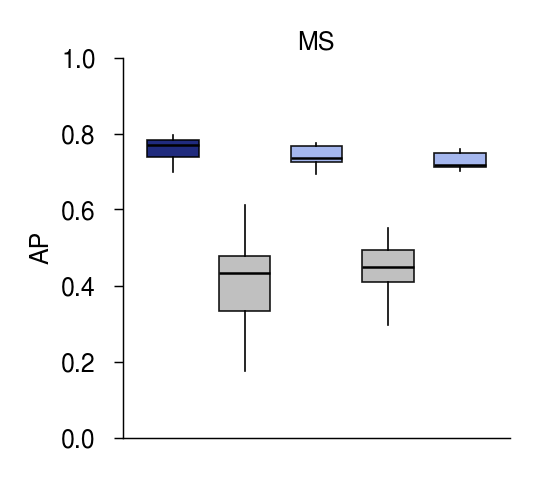

In [ ]:
# matched ms performance distribution
"""
Plotting parameters for yeast display, BA, and ESCAPE-seq assay and MS boxplots.
"""
score_cols=["mhcprime", "episcan_r9_ft", "episcan_r9_pepcl", "episcan_r9rt_ft", "episcan_r9rt_pepcl"]

model_groups = {
    'MHCPrime': ["mhcprime"],
    'FT R9': ["episcan_r9_ft"],
    'PepCL R9': ["episcan_r9_pepcl"],
    'FT R9RT': ["episcan_r9rt_ft"],
    'PepCL R9RT': ["episcan_r9rt_pepcl"],
}


x_ticks = ['']
print(model_groups)

colors = {
    'MHCPrime': '#081470',
    'FT R9': '#bababa',
    'FT R9RT': '#bababa',
    'PepCL R9': '#9bb0ed',
    'PepCL R9RT': '#9bb0ed',

}

plot_params = {
    'title': '',
    'title_y': 1.04,
    'title_bbox': None,

    # 'title_fontsize': 7,
    'title_fontsize': 6,
    'title_bold': False,
    'xlabel': '',
    'ylabel': 'AP',
    # 'xlabel_fontsize': 7,
    # 'ylabel_fontsize': 7,
    'xlabel_fontsize': 6,
    'ylabel_fontsize': 6,
    # 'figsize': (1.20, 1.65),
    'figsize': (1.90, 1.65),  # scaled from 3 boxes to 5 boxes
    'dpi': 300,
    'legend_fontsize': 6,
    'legend_cols': 3,
    'legend_handle_size': 0.7,
    'axis_linewidth': 0.35,
    # 'axis_linewidth': 0.30,
    # 'axis_linewidth': 0.25,
    'tick_length': 2.2,
    'xlabel_pad': 1,
    'ylabel_pad': 1.5,
    'xtick_labelsize': 5.5,
    'ytick_labelsize': 6,
}

plotting_parameters = dict(
    model_col='model_name',
    score_col='metric',
    model_groups=model_groups,
    x_ticks=[''],
    colors=colors,
    plot_params=plot_params,
    ylim=(0.0, 1.0),
    grid_alpha=0,
    default_font='Nimbus Sans',
    mode='box',
    bar_width=0.32,
    bar_spacing=0.08,
    group_spacing=0.10,
    x_margin=0.12,
    bar_outline_color='black',
    box_median_width=0.60,
    # bar_outline_width=0.35,
    # box_whisker_width=0.30,
    bar_outline_width=0.40,
    box_whisker_width=0.40,
    box_flier_size=0,
    legend_mode=None,
    xtick_rotation=0,

    pval_df=None,
    pval_fontsize=4,
    pval_linewidth=0.35,
    pval_color='black',
    pval_bar_offset=0.035,
    pval_bar_spacing=0.06,
    pval_text_offset=0.004,
    pval_star_text_offset=-0.01,
    pval_ns_text_offset=0.004,
)


plot_params['title']='MS'
plotting_parameters['plot_params']=plot_params
_=plot_model_performance_bars_or_box_v2(
    df=ms_episcan_allele_ap_df,
    save_path=None,
    # save_path=f"{central_figure_dir}/fig5_a_ms_matched_for_episcan_cov_transfer_learning_boxplots",
    **plotting_parameters
)


In [ ]:
"""
Save dataframes associated with figures.
"""
save_dfs=False
# save_dfs=True

if save_dfs:
    # ap dfs
    sd3_allele_ap_matrix.to_csv(f"{associated_data_dir}/sd3_allele_ap_matrix.csv")
    ms_episcan_allele_ap_df.to_csv(f"{associated_data_dir}/ms_episcan_allele_ap_df.csv")

### Fig. 5b: Yeast display

In [ ]:
%%time
# get holec and matched ms sets
outputs_dir = DATA_DIR / "Holec_Single_Allele_Heldout_Tranfer_Learning_Outputs" / "output_dfs"
file_name_pattern="holec_allele_test_set"
holec_allele_test_set_full=get_transfer_learning_outputs(outputs_dir, file_name_pattern)

file_name_pattern="ms_allele_test_set"
ms_holec_allele_test_set_full=get_transfer_learning_outputs(outputs_dir, file_name_pattern)
ms_holec_allele_test_set_full["seq_len"]=ms_holec_allele_test_set_full.seq.str.replace("$", "").apply(len)
ms_holec_allele_test_set_full_9mers=ms_holec_allele_test_set_full.query("seq_len == 9")

100%|██████████| 32/32 [00:01<00:00, 26.11it/s]


CPU times: user 7.52 s, sys: 684 ms, total: 8.21 s
Wall time: 8.18 s


In [ ]:
# number of alleles
print("N alleles: ", holec_allele_test_set_full.allele.nunique())

N alleles:  16


In [ ]:
%%time
# get iterative ap per allele
score_cols=["mhcprime", "model_ft", "model_pepcl"]

n_iterations=100
neg_ratio=99

holec_allele_ap_df=mean_ap_by_allele_resampled_v2(
    df=holec_allele_test_set_full,
    score_cols=score_cols,
    allele_col = "allele",
    label_col = "label",
    n_pos = 200,
    pos_to_neg_ratio = 99,
    n_iter = 100,
    seed = 42,
    use_max_possible_pos=True,
)

Alleles: 100%|██████████| 16/16 [00:42<00:00,  2.64s/it]

CPU times: user 42.4 s, sys: 29.2 ms, total: 42.4 s
Wall time: 42.4 s


In [ ]:
# matched ms performance
score_cols=["mhcprime", "model_ft", "model_pepcl"]

ms_holec_allele_ap_df=compute_ap_matrix_optimized(ms_holec_allele_test_set_full_9mers, score_cols, label_col="label", allele_col='allele')

100%|██████████| 16/16 [00:00<00:00, 191.24it/s]


In [ ]:
# compute p-values for yd data
score_cols=["mhcprime", "model_ft", "model_pepcl"]

holec_pval_df=compute_pairwise_pvalues_general(holec_allele_ap_df[score_cols])

display(holec_pval_df)
display(pval_to_stars(holec_pval_df))

,mhcprime,model_ft,model_pepcl
mhcprime,1.000000,0.000305,0.000031
model_ft,0.000305,1.000000,0.820892
model_pepcl,0.000031,0.820892,1.000000


,mhcprime,model_ft,model_pepcl
mhcprime,ns,***,****
model_ft,***,ns,ns
model_pepcl,****,ns,ns


In [ ]:
# compute p-values for matched ms data
score_cols=["mhcprime", "model_ft", "model_pepcl"]

ms_holec_pval_df=compute_pairwise_pvalues_general(ms_holec_allele_ap_df[score_cols])

display(ms_holec_pval_df)
display(pval_to_stars(ms_holec_pval_df))

,mhcprime,model_ft,model_pepcl
mhcprime,1.000000,0.000031,0.000214
model_ft,0.000031,1.000000,0.000031
model_pepcl,0.000214,0.000031,1.000000


,mhcprime,model_ft,model_pepcl
mhcprime,ns,****,***
model_ft,****,ns,****
model_pepcl,***,****,ns


In [ ]:
"""
Plotting parameters for yeast display, BA, and ESCAPE-seq assay and MS boxplots.
"""
score_cols=["mhcprime", "model_ft", "model_pepcl"]

model_groups = {
    'MHCPrime': ["mhcprime"],
    'FT': ["model_ft"],
    'PepCL': ["model_pepcl"],
}

x_ticks = ['']
print(model_groups)

colors = {
    'MHCPrime': '#081470',
    'FT': '#bababa',
    'PepCL': '#9bb0ed',
}

plot_params = {
    'title': '',
    'title_y': 1.04,
    'title_bbox': None,

    # 'title_fontsize': 7,
    'title_fontsize': 6,
    'title_bold': False,
    'xlabel': '',
    'ylabel': 'AP',
    # 'xlabel_fontsize': 7,
    # 'ylabel_fontsize': 7,
    'xlabel_fontsize': 6,
    'ylabel_fontsize': 6,
    'figsize': (1.20, 1.65),
    'dpi': 300,
    'legend_fontsize': 6,
    'legend_cols': 3,
    'legend_handle_size': 0.7,
    'axis_linewidth': 0.35,
    # 'axis_linewidth': 0.30,
    # 'axis_linewidth': 0.25,
    'tick_length': 2.2,
    'xlabel_pad': 1,
    'ylabel_pad': 1.5,
    'xtick_labelsize': 5.5,
    'ytick_labelsize': 6,
}

plotting_parameters = dict(
    model_col='model_name',
    score_col='metric',
    model_groups=model_groups,
    x_ticks=[''],
    colors=colors,
    plot_params=plot_params,
    ylim=(0.0, 1.0),
    grid_alpha=0,
    default_font='Nimbus Sans',
    mode='box',
    bar_width=0.32,
    bar_spacing=0.08,
    group_spacing=0.10,
    x_margin=0.12,
    bar_outline_color='black',
    box_median_width=0.60,
    # bar_outline_width=0.35,
    # box_whisker_width=0.30,
    bar_outline_width=0.40,
    box_whisker_width=0.40,
    box_flier_size=0,
    legend_mode=None,
    xtick_rotation=0,

    pval_df=None,
    pval_fontsize=4,
    pval_linewidth=0.35,
    pval_color='black',
    pval_bar_offset=0.035,
    pval_bar_spacing=0.06,
    pval_text_offset=0.004,
    pval_star_text_offset=-0.01,
    pval_ns_text_offset=0.004,
    pval_merge_nonoverlapping=False

)

{'MHCPrime': ['mhcprime'], 'FT': ['model_ft'], 'PepCL': ['model_pepcl']}


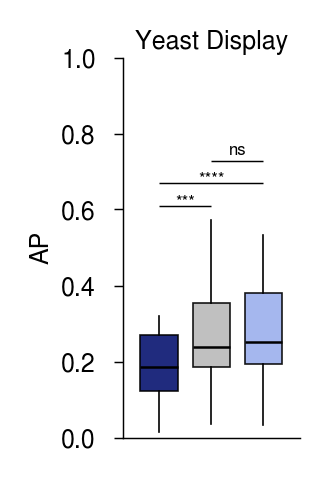

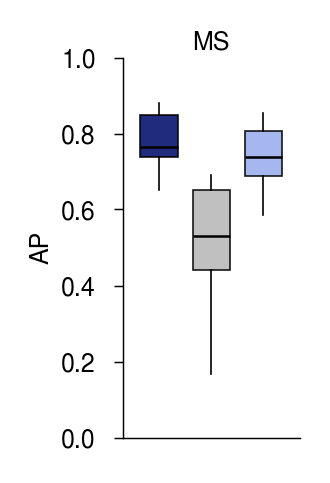

(<Figure size 360x495 with 1 Axes>, <Axes: ylabel='AP'>)

In [ ]:
# plot boxplots for holec performance
plot_params['title']='Yeast Display'
plotting_parameters['plot_params']=plot_params
plotting_parameters["pval_df"]=holec_pval_df
plot_model_performance_bars_or_box_v2(
    df=holec_allele_ap_df,
    save_path=None,
    # save_path=f"{central_figure_dir}/fig5_b_yeast_display_transfer_learning_boxplots",
    **plotting_parameters
)

plot_params['title']='MS'
plotting_parameters['plot_params']=plot_params
plotting_parameters["pval_df"]=None
plot_model_performance_bars_or_box_v2(
    df=ms_holec_allele_ap_df,
    save_path=None,
    # save_path=f"{central_figure_dir}/fig5_b_ms_matched_for_yeast_display_transfer_learning_boxplots",
    **plotting_parameters
)

In [ ]:
"""
Save dataframes associated with figures.
"""
save_dfs=False
# save_dfs=True

if save_dfs:
    # ap dfs
    holec_allele_ap_df.to_csv(f"{associated_data_dir}/holec_allele_ap_df.csv")
    ms_holec_allele_ap_df.to_csv(f"{associated_data_dir}/ms_holec_allele_ap_df.csv")

    # p-value dfs
    holec_pval_df.to_csv(f"{associated_data_dir}/holec_pval_df.csv")
    ms_holec_pval_df.to_csv(f"{associated_data_dir}/ms_holec_pval_df.csv")

### Fig. 5c: BA

In [ ]:
%%time
# get ba and matched ms sets
outputs_dir = DATA_DIR / "BA_Single_Allele_Heldout_Tranfer_Learning_Outputs" / "output_dfs"
file_name_pattern="ba_allele_test_set"
ba_allele_test_set_full=get_transfer_learning_outputs(outputs_dir, file_name_pattern)
ba_allele_test_set_full["seq_len"]=ba_allele_test_set_full.seq.str.replace("$", "").apply(len)
ba_allele_test_set_full_9mers=ba_allele_test_set_full.query("seq_len == 9")

file_name_pattern="ms_allele_test_set"
ms_ba_allele_test_set_full=get_transfer_learning_outputs(outputs_dir, file_name_pattern)
ms_ba_allele_test_set_full["seq_len"]=ms_ba_allele_test_set_full.seq.str.replace("$", "").apply(len)
ms_ba_allele_test_set_full_9mers=ms_ba_allele_test_set_full.query("seq_len == 9")

100%|██████████| 76/76 [00:05<00:00, 14.39it/s]


CPU times: user 7.11 s, sys: 655 ms, total: 7.76 s
Wall time: 7.72 s


In [ ]:
# number of alleles
print("N alleles: ", ba_allele_test_set_full_9mers.allele.nunique())

N alleles:  38


In [ ]:
%%time
# get iterative ap per allele
score_cols=["mhcprime", "model_ft", "model_pepcl"]

n_iterations=100
neg_ratio=99

ba_allele_ap_df=mean_ap_by_allele_resampled_v2(
    df=ba_allele_test_set_full_9mers,
    score_cols=score_cols,
    allele_col = "allele",
    label_col = "label",
    n_pos = 200,
    pos_to_neg_ratio = 99,
    n_iter = 100,
    seed = 42,
    use_max_possible_pos=True,
)

Alleles: 100%|██████████| 38/38 [00:06<00:00,  6.21it/s]

CPU times: user 6.17 s, sys: 13.1 ms, total: 6.18 s
Wall time: 6.17 s


In [ ]:
# matched ms performance
score_cols=["mhcprime", "model_ft", "model_pepcl"]

ms_ba_allele_ap_df=compute_ap_matrix_optimized(ms_ba_allele_test_set_full_9mers, score_cols, label_col="label", allele_col='allele')

  0%|          | 0/38 [00:00<?, ?it/s]

100%|██████████| 38/38 [00:00<00:00, 193.02it/s]


In [ ]:
# compute p-values for ba data
score_cols=["mhcprime", "model_ft", "model_pepcl"]

ba_pval_df=compute_pairwise_pvalues_general(ba_allele_ap_df[score_cols])

display(ba_pval_df)
display(pval_to_stars(ba_pval_df))

,mhcprime,model_ft,model_pepcl
mhcprime,1.000000e+00,3.135938e-08,2.011802e-08
model_ft,3.135938e-08,1.000000e+00,9.087139e-01
model_pepcl,2.011802e-08,9.087139e-01,1.000000e+00


,mhcprime,model_ft,model_pepcl
mhcprime,ns,****,****
model_ft,****,ns,ns
model_pepcl,****,ns,ns


In [ ]:
# compute p-values for matched ms
score_cols=["mhcprime", "model_ft", "model_pepcl"]

ms_ba_pval_df=compute_pairwise_pvalues_general(ms_ba_allele_ap_df[score_cols])

display(ms_ba_pval_df)
display(pval_to_stars(ms_ba_pval_df))

,mhcprime,model_ft,model_pepcl
mhcprime,1.000000e+00,7.275958e-12,7.275958e-12
model_ft,7.275958e-12,1.000000e+00,7.275958e-12
model_pepcl,7.275958e-12,7.275958e-12,1.000000e+00


,mhcprime,model_ft,model_pepcl
mhcprime,ns,****,****
model_ft,****,ns,****
model_pepcl,****,****,ns


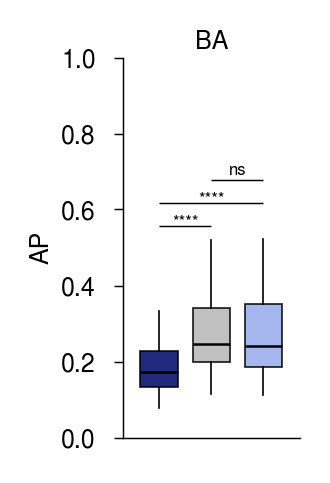

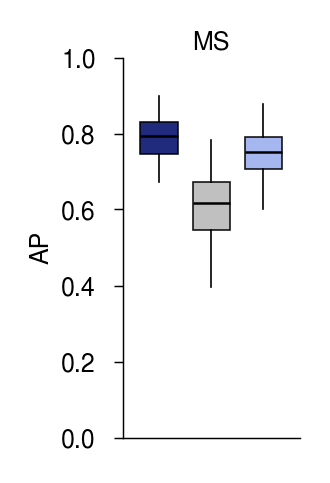

(<Figure size 360x495 with 1 Axes>, <Axes: ylabel='AP'>)

In [ ]:
# plot boxplots for ba performance
plot_params['title']='BA'
plotting_parameters['plot_params']=plot_params
plotting_parameters["pval_df"]=ba_pval_df
plot_model_performance_bars_or_box_v2(
    df=ba_allele_ap_df,
    save_path=None,
    # save_path=f"{central_figure_dir}/fig5_c_ba_transfer_learning_boxplots",
    **plotting_parameters
)

plot_params['title']='MS'
plotting_parameters['plot_params']=plot_params
plotting_parameters["pval_df"]=None
plot_model_performance_bars_or_box_v2(
    df=ms_ba_allele_ap_df,
    save_path=None,
    # save_path=f"{central_figure_dir}/fig5_c_ms_matched_for_ba_transfer_learning_boxplots",
    **plotting_parameters
)

In [ ]:
"""
Save dataframes associated with figures.
"""
save_dfs=False
# save_dfs=True

if save_dfs:
    # ap dfs
    ba_allele_ap_df.to_csv(f"{associated_data_dir}/ba_allele_ap_df.csv")
    ms_ba_allele_ap_df.to_csv(f"{associated_data_dir}/ms_ba_allele_ap_df.csv")

    # p-value dfs
    ba_pval_df.to_csv(f"{associated_data_dir}/ba_pval_df.csv")
    ms_ba_pval_df.to_csv(f"{associated_data_dir}/ms_ba_pval_df.csv")

### Fig. 5d: ESCAPE-seq

In [ ]:
%%time
# get escape and matched ms sets
outputs_dir = DATA_DIR / "ESCAPE_seq_Single_Allele_Heldout_Tranfer_Learning_Outputs" / "output_dfs"
file_name_pattern="escape_allele_test_set"
escape_allele_test_set_full=get_transfer_learning_outputs(outputs_dir, file_name_pattern)

file_name_pattern="ms_allele_test_set"
ms_escape_allele_test_set_full=get_transfer_learning_outputs(outputs_dir, file_name_pattern)
ms_escape_allele_test_set_full["seq_len"]=ms_escape_allele_test_set_full.seq.str.replace("$", "").apply(len)
ms_escape_allele_test_set_full_9mers=ms_escape_allele_test_set_full.query("seq_len == 9")

100%|██████████| 88/88 [00:05<00:00, 14.91it/s]


CPU times: user 8.11 s, sys: 474 ms, total: 8.58 s
Wall time: 8.55 s


In [ ]:
# number of alleles
print("N alleles: ", escape_allele_test_set_full.allele.nunique())

N alleles:  44


In [ ]:
%%time
# get iterative ap per allele
score_cols=["mhcprime", "model_ft", "model_pepcl"]

n_iterations=100
neg_ratio=99

escape_allele_ap_df=mean_ap_by_allele_resampled_v2(
    df=escape_allele_test_set_full,
    score_cols=score_cols,
    allele_col = "allele",
    label_col = "label",
    n_pos = 200,
    pos_to_neg_ratio = 99,
    n_iter = 100,
    seed = 42,
    use_max_possible_pos=True,
)

Alleles: 100%|██████████| 44/44 [00:05<00:00,  7.33it/s]

CPU times: user 6.04 s, sys: 20.2 ms, total: 6.06 s
Wall time: 6.04 s


In [ ]:
# matched ms performance
score_cols=["mhcprime", "model_ft", "model_pepcl"]

ms_escape_allele_ap_df=compute_ap_matrix_optimized(ms_escape_allele_test_set_full_9mers, score_cols, label_col="label", allele_col='allele')

100%|██████████| 44/44 [00:00<00:00, 189.94it/s]


In [ ]:
# compute p-values for escape-seq data
score_cols=["mhcprime", "model_ft", "model_pepcl"]

escape_pval_df=compute_pairwise_pvalues_general(escape_allele_ap_df[score_cols])

display(escape_pval_df)
display(pval_to_stars(escape_pval_df))

,mhcprime,model_ft,model_pepcl
mhcprime,1.000000e+00,1.557510e-11,2.273737e-13
model_ft,1.557510e-11,1.000000e+00,5.284287e-01
model_pepcl,2.273737e-13,5.284287e-01,1.000000e+00


,mhcprime,model_ft,model_pepcl
mhcprime,ns,****,****
model_ft,****,ns,ns
model_pepcl,****,ns,ns


In [ ]:
# compute p-values for matched ms
score_cols=["mhcprime", "model_ft", "model_pepcl"]

ms_escape_pval_df=compute_pairwise_pvalues_general(ms_escape_allele_ap_df[score_cols])

display(ms_escape_pval_df)
display(pval_to_stars(ms_escape_pval_df))

,mhcprime,model_ft,model_pepcl
mhcprime,1.000000e+00,1.136868e-13,2.871549e-06
model_ft,1.136868e-13,1.000000e+00,1.136868e-13
model_pepcl,2.871549e-06,1.136868e-13,1.000000e+00


,mhcprime,model_ft,model_pepcl
mhcprime,ns,****,****
model_ft,****,ns,****
model_pepcl,****,****,ns


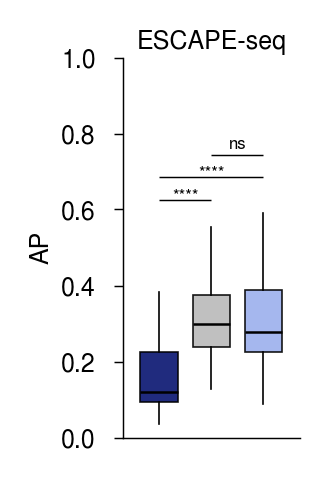

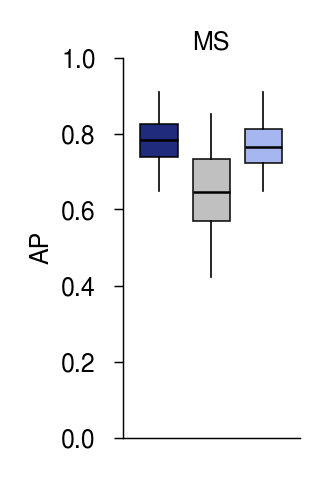

(<Figure size 360x495 with 1 Axes>, <Axes: ylabel='AP'>)

In [ ]:
# plot boxplots for escape-seq performance
plot_params['title']='ESCAPE-seq'
plotting_parameters['plot_params']=plot_params
plotting_parameters["pval_df"]=escape_pval_df
plot_model_performance_bars_or_box_v2(
    df=escape_allele_ap_df,
    save_path=None,
    # save_path=f"{central_figure_dir}/fig5_d_escape_seq_transfer_learning_boxplots",
    **plotting_parameters
)

plot_params['title']='MS'
plotting_parameters['plot_params']=plot_params
plotting_parameters["pval_df"]=None
plot_model_performance_bars_or_box_v2(
    df=ms_escape_allele_ap_df,
    save_path=None,
    # save_path=f"{central_figure_dir}/fig5_d_ms_matched_for_escape_seq_transfer_learning_boxplots",
    **plotting_parameters
)

In [ ]:
"""
Save dataframes associated with figures.
"""
save_dfs=False
# save_dfs=True

if save_dfs:
    # ap dfs
    escape_allele_ap_df.to_csv(f"{associated_data_dir}/escape_allele_ap_df.csv")
    ms_escape_allele_ap_df.to_csv(f"{associated_data_dir}/ms_escape_allele_ap_df.csv")

    # p-value dfs
    escape_pval_df.to_csv(f"{associated_data_dir}/escape_pval_df.csv")
    ms_escape_pval_df.to_csv(f"{associated_data_dir}/ms_escape_pval_df.csv")

### Fig. 5b-d: Plot yeast display, BA, and ESCAPE-seq together

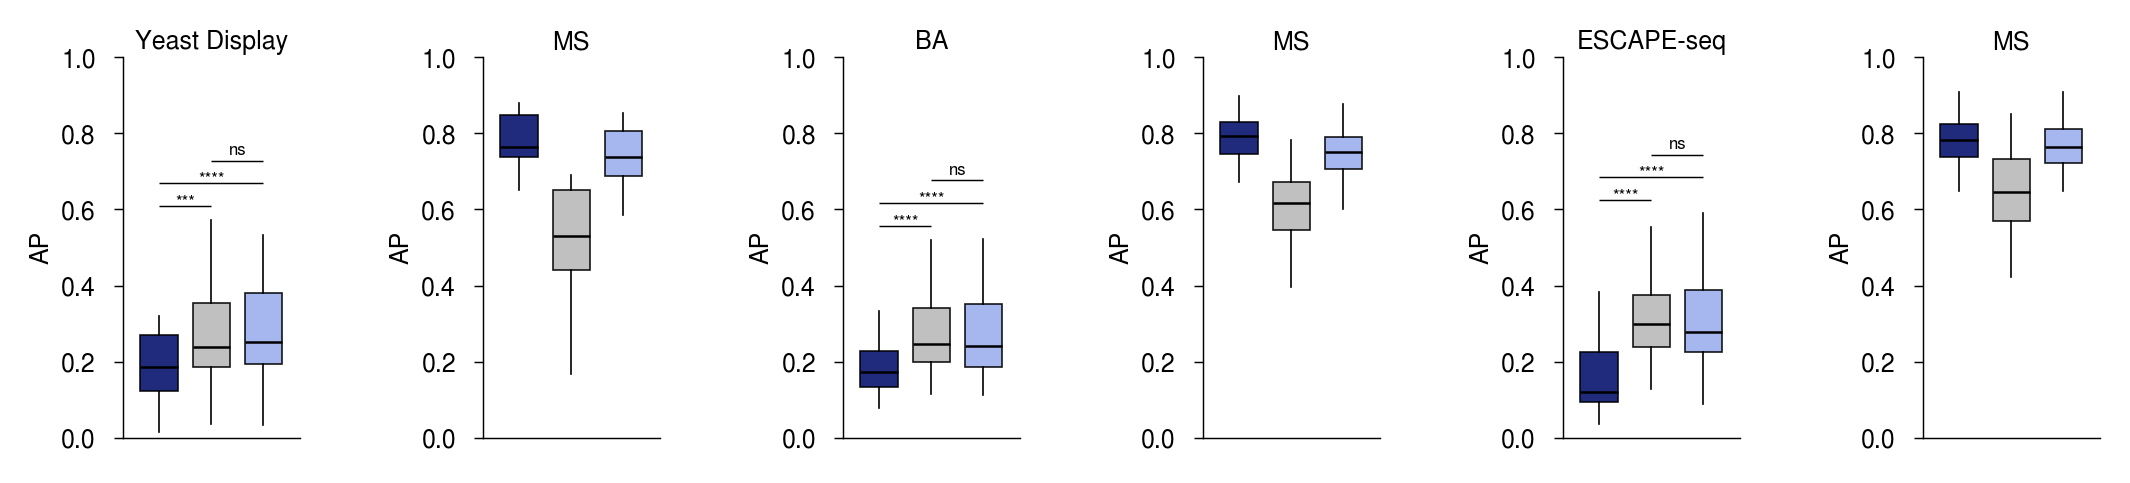

In [ ]:
# plot all together
plot_dict = {
    'yeast_display': {
        'title': 'Yeast Display',
        'df': holec_allele_ap_df,
        'pval_df': holec_pval_df,
    },
    'ms_for_yeast': {
        'title': 'MS',
        'df': ms_holec_allele_ap_df,
    },
    'ba': {
        'title': 'BA',
        'df': ba_allele_ap_df,
        'pval_df': ba_pval_df,
    },
    'ms_for_ba': {
        'title': 'MS',
        'df': ms_ba_allele_ap_df,
    },
    'escape_seq': {
        'title': 'ESCAPE-seq',
        'df': escape_allele_ap_df,
        'pval_df': escape_pval_df,
    },
    'ms_for_escape': {
        'title': 'MS',
        'df': ms_escape_allele_ap_df,
    },
}

fig, axes = plot_model_performance_box_grid_v2(
    plot_dict=plot_dict,
    save_path=None,
    # save_path=f"{central_figure_dir}/fig5_bcd_yd_ba_escape_with_ms_transfer_learning_boxplots",
    panel_gap=0.00,
    grid_dpi=300,
    **plotting_parameters,
)
